# AI 智能找矿 — 无监督学习 MVP（自编码器主线）

**项目**：大创项目 "AI 智能找矿"  
**方法**：前馈神经网络 — 自编码器（AE）重建误差异常检测  
**基线**：IsolationForest（经典无监督基线，仅作对比）  
**数据**：甲玛矿区地表土壤化探 9,021 点 × 49 元素；钻孔 477 孔 / 114,082 段化验（独立验证）

## 流水线总览
1. 读表 → 2. 坐标核验（钻孔去带号对齐）→ 3. 特征工程（0→NaN, log1p, 标准化）
4. AE 训练（49→32→16→8→16→32→49, MSE, 早停）→ 5. 异常评分（重建 MSE 归一化）
6. IsolationForest 基线 → 7. 钻孔独立验证（CuEq 圈矿化, 命中率/AUC, GroupKFold）
8. 交付：异常分数表 + 预测图 + 靶区清单 + AE-vs-IF 对比

> **红线**：钻孔只在验证环节出现，永不拼进特征矩阵；AE 训练只用土壤 49 元素。

In [1]:
# === 导入与全局配置 ===
import os, sys, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.colors import LogNorm

from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.cluster import DBSCAN
from scipy.spatial import cKDTree

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings('ignore')
%matplotlib inline

# 中文字体
matplotlib.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
matplotlib.rcParams['axes.unicode_minus'] = False

# 随机种子
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# 设备
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch 设备: {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU: {torch.cuda.get_device_name(0)}')

# 路径
SOIL_PATH  = r'D:\project\mymine\data\Jiama geochemistry data 2020.8.30-iogas.xlsx'
DRILL_PATH = r'D:\project\mymine\data\数据库-川大 2025.4.29.xlsx'
OUTPUT_DIR = r'D:\project\mymine\output'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print(f'输出目录: {OUTPUT_DIR}')

PyTorch 设备: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
输出目录: D:\project\mymine\output


## Step 1 — 读取数据

In [2]:
# === 1.1 土壤化探数据 ===
df_soil = pd.read_excel(SOIL_PATH, sheet_name='data')
# 去除列名首尾空格
df_soil.columns = df_soil.columns.str.strip()
print(f'土壤数据: {df_soil.shape[0]} 行 × {df_soil.shape[1]} 列')
print(f'列名: {list(df_soil.columns)}')
print(f'\nEast 范围: {df_soil["East"].min():.0f} ~ {df_soil["East"].max():.0f}')
print(f'North 范围: {df_soil["North"].min():.0f} ~ {df_soil["North"].max():.0f}')
print(f'Cu ppm 最大: {df_soil["Cu ppm"].max():.1f}')
print(f'H 缺失率: {df_soil["H"].isna().mean():.1%}')
print(f'rock type 缺失率: {df_soil["rock type"].isna().mean():.1%}')
df_soil.head(3)

土壤数据: 9021 行 × 55 列
列名: ['Analysis No', 'East', 'North', 'sample type', 'Al2O3 %', 'CaO %', 'CaO R %', 'MgO %', 'K2O %', 'Na2O %', 'Fe2O3 %', 'MnO %', 'P2O5 %', 'TiO2 %', 'S ppm', 'Cu ppm', 'Li ppm', 'Ni ppm', 'Rb ppm', 'Co ppm', 'Sr ppm', 'V ppm', 'Zn ppm', 'Ba ppm', 'Be ppm', 'Cr ppm', 'Ga ppm', 'Mo ppm', 'Nb ppm', 'Pb ppm', 'Sc ppm', 'W ppm', 'Y ppm', 'Zr ppm', 'Bi ppm', 'Cd ppm', 'Ce ppm', 'Cs ppm', 'Ge ppm', 'Hf ppm', 'In ppm', 'La ppm', 'Re ppm', 'Se ppm', 'Ta ppm', 'Te ppm', 'Th ppm', 'Tl ppm', 'U ppm', 'As ppm', 'Sb ppm', 'Ag ppm', 'Sn ppm', 'H', 'rock type']

East 范围: 374235 ~ 384798
North 范围: 3277714 ~ 3292001
Cu ppm 最大: 354700.0
H 缺失率: 78.1%
rock type 缺失率: 78.2%


,Analysis No,East,North,sample type,Al2O3 %,CaO %,CaO R %,MgO %,K2O %,Na2O %,...,Te ppm,Th ppm,Tl ppm,U ppm,As ppm,Sb ppm,Ag ppm,Sn ppm,H,rock type
0,2011784-154,377627.0,3277714.0,Soil-B,13.77,0.902484,1.262756,1.019025,2.513,1.481,...,0.059834,17.181,0.922,2.954,30.6528,1.7686,0.080,3.72,NaN,NaN
1,2011784-153,377736.0,3277780.0,Soil-B,12.17,1.712621,2.396299,1.450349,2.123,1.901,...,0.061369,16.610,0.711,2.597,19.1327,1.3468,0.074,3.82,NaN,NaN
2,2011784-152,377791.0,3277882.0,Soil-B,13.28,1.306013,1.827374,1.109900,2.300,1.662,...,0.072108,17.476,0.833,2.674,26.0307,1.5732,0.080,3.93,NaN,NaN


In [3]:
# === 1.2 钻孔数据 ===
df_pos = pd.read_excel(DRILL_PATH, sheet_name='空间位置')
df_ana = pd.read_excel(DRILL_PATH, sheet_name='分析数据')
df_pos.columns = df_pos.columns.str.strip()
df_ana.columns = df_ana.columns.str.strip()
print(f'钻孔空间位置: {df_pos.shape[0]} 孔 × {df_pos.shape[1]} 列')
print(f'钻孔分析数据: {df_ana.shape[0]} 段 × {df_ana.shape[1]} 列')
print(f'\n空间位置列: {list(df_pos.columns)}')
print(f'分析数据列: {list(df_ana.columns)}')
print(f'\nEAST 原始范围: {df_pos["EAST"].min():.2f} ~ {df_pos["EAST"].max():.2f}')
print(f'NORTH 范围: {df_pos["NORTH"].min():.2f} ~ {df_pos["NORTH"].max():.2f}')

钻孔空间位置: 477 孔 × 6 列
钻孔分析数据: 114082 段 × 13 列

空间位置列: ['HOLE', 'EAST', 'NORTH', 'H 海拔', 'TDEPTH', '勘探线']
分析数据列: ['HOLE', 'FROM', 'TO', 'INT', 'SAMPLE-ID', 'Au ppm', 'Ag ppm', 'Cu %', 'Mo %', 'Pb %', 'Zn %', '勘探类型', '岩性']

EAST 原始范围: 31378143.57 ~ 31381150.69
NORTH 范围: 3286298.63 ~ 3290422.05


## Step 2 — 坐标核验（先行）

钻孔 EAST 带 31 度带号（如 31,378,863），需减去 31,000,000 去带号，再与土壤 East（374k~385k）对齐。

In [4]:
# === 2.1 去带号 ===
df_pos['EAST_corr'] = df_pos['EAST'] - 31_000_000
print(f'钻孔 EAST 去带号后: {df_pos["EAST_corr"].min():.1f} ~ {df_pos["EAST_corr"].max():.1f}')
print(f'土壤 East:           {df_soil["East"].min():.0f} ~ {df_soil["East"].max():.0f}')
print(f'钻孔 NORTH:          {df_pos["NORTH"].min():.1f} ~ {df_pos["NORTH"].max():.1f}')
print(f'土壤 North:          {df_soil["North"].min():.0f} ~ {df_soil["North"].max():.0f}')

# 检查重叠
east_overlap = (df_pos['EAST_corr'].min() < df_soil['East'].max()) and (df_pos['EAST_corr'].max() > df_soil['East'].min())
north_overlap = (df_pos['NORTH'].min() < df_soil['North'].max()) and (df_pos['NORTH'].max() > df_soil['North'].min())
print(f'\nEast 重叠: {east_overlap}, North 重叠: {north_overlap}')
print('=> 同一甲玛矿区坐标系统一确认' if (east_overlap and north_overlap) else '=> 坐标不重叠，需检查！')

钻孔 EAST 去带号后: 378143.6 ~ 381150.7
土壤 East:           374235 ~ 384798
钻孔 NORTH:          3286298.6 ~ 3290422.0
土壤 North:          3277714 ~ 3292001

East 重叠: True, North 重叠: True
=> 同一甲玛矿区坐标系统一确认


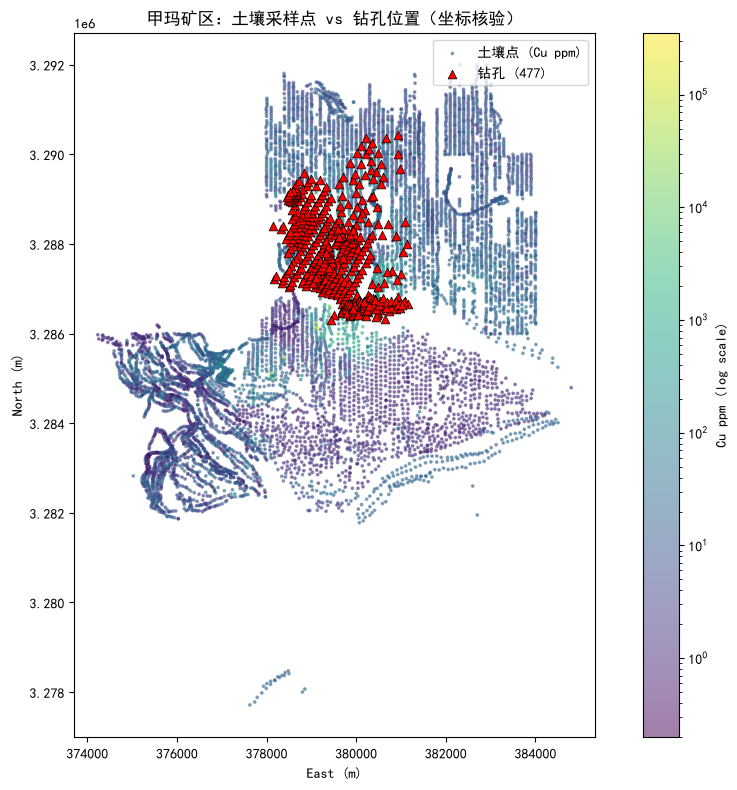

坐标核验图已保存


In [5]:
# === 2.2 空间分布可视化 ===
fig, ax = plt.subplots(figsize=(10, 8))
sc = ax.scatter(df_soil['East'], df_soil['North'], c=df_soil['Cu ppm'],
                cmap='viridis', norm=LogNorm(), s=3, alpha=0.5, label='土壤点 (Cu ppm)')
ax.scatter(df_pos['EAST_corr'], df_pos['NORTH'], c='red', marker='^', s=40,
           edgecolors='black', linewidths=0.5, label='钻孔 (477)')
ax.set_xlabel('East (m)')
ax.set_ylabel('North (m)')
ax.set_title('甲玛矿区：土壤采样点 vs 钻孔位置（坐标核验）')
ax.legend(loc='upper right')
plt.colorbar(sc, ax=ax, label='Cu ppm (log scale)')
ax.set_aspect('equal')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '01_coordinate_verification.png'), dpi=150)
plt.show()
print('坐标核验图已保存')

## Step 3 — 特征工程

**规则**：
- 特征矩阵 = 土壤 49 元素列（10 主量元素氧化物 % + S + 38 微量元素 ppm）
- 弃用：H、rock type（缺失率 ~78%）、Analysis No、sample type、East/North
- 0 → NaN（低于检出限）→ log1p 变换 → 中位数填充 → StandardScaler 标准化

In [ ]:
# === 3.1 识别 49 特征列 ===
# 特征列 = sample type 之后、H 之前的所有列
all_cols = list(df_soil.columns)
start_idx = all_cols.index('sample type') + 1
end_idx = all_cols.index('H')
feature_cols = all_cols[start_idx:end_idx]
print(f'特征列数量: {len(feature_cols)}')
print(f'特征列: {feature_cols}')

# 提取特征矩阵
X_raw = df_soil[feature_cols].copy()
print(f'\n原始特征矩阵: {X_raw.shape}')
print(f'含 0 值的单元格数: {(X_raw == 0).sum().sum()}')
print(f'含 NaN 的单元格数: {X_raw.isna().sum().sum()}')

In [ ]:
# === 3.2 0→NaN, log1p, 中位数填充, 标准化 ===
# Step 1: 0 → NaN
X = X_raw.replace(0, np.nan)
print(f'0→NaN 后缺失数: {X.isna().sum().sum()}')

# Step 2: log1p 变换（对正值稳定，NaN 保持 NaN）
X_log = np.log1p(X)

# Step 3: 中位数填充（按列）
medians = X_log.median()
X_log_filled = X_log.fillna(medians)
print(f'填充后缺失数: {X_log_filled.isna().sum().sum()}')

# Step 4: StandardScaler 标准化
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log_filled)
print(f'标准化后 shape: {X_scaled.shape}')
print(f'标准化后 mean≈0: {X_scaled.mean():.6f}, std≈1: {X_scaled.std():.6f}')

# 保存坐标用于后续
coords = df_soil[['East', 'North']].values
print(f'\n特征矩阵就绪: {X_scaled.shape[0]} 点 × {X_scaled.shape[1]} 维')

## Step 4 — 自编码器（AE）训练

**架构**：49 → 32 → 16 → 8（瓶颈）→ 16 → 32 → 49  
**激活**：ReLU（输出层无激活，重建连续值）  
**损失**：MSE  
**优化器**：Adam, lr=1e-3  
**批次**：128  
**正则**：早停（patience=15）防过拟合  
**数据**：全量 9,021 点无标签重建

In [ ]:
# === 4.1 AE 模型定义 ===
class Autoencoder(nn.Module):
    def __init__(self, input_dim=49, latent_dim=8):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, latent_dim),
            nn.ReLU(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 16),
            nn.ReLU(),
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, input_dim),
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

model = Autoencoder(input_dim=X_scaled.shape[1], latent_dim=8).to(DEVICE)
print(model)
total_params = sum(p.numel() for p in model.parameters())
print(f'\n总参数量: {total_params:,}（小网络，防过拟合）')

In [ ]:
# === 4.2 训练函数（含早停） ===
def train_ae(X_data, epochs=300, batch_size=128, lr=1e-3, patience=15, device=DEVICE):
    model = Autoencoder(input_dim=X_data.shape[1], latent_dim=8).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss()

    dataset = TensorDataset(torch.FloatTensor(X_data))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=False)

    best_loss = float('inf')
    best_state = None
    counter = 0
    history = []

    for epoch in range(epochs):
        model.train()
        total_loss = 0.0
        n_samples = 0
        for (batch,) in loader:
            batch = batch.to(device)
            optimizer.zero_grad()
            recon = model(batch)
            loss = criterion(recon, batch)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(batch)
            n_samples += len(batch)

        avg_loss = total_loss / n_samples
        history.append(avg_loss)

        # 早停
        if avg_loss < best_loss - 1e-6:
            best_loss = avg_loss
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                print(f'  早停于 epoch {epoch+1}, best_loss={best_loss:.6f}')
                break

        if (epoch + 1) % 20 == 0:
            print(f'  Epoch {epoch+1}/{epochs}, loss={avg_loss:.6f}')

    model.load_state_dict(best_state)
    return model, history

print('开始训练 AE ...')
ae_model, train_history = train_ae(X_scaled, epochs=300, batch_size=128, lr=1e-3, patience=15)
print(f'训练完成，最终 best_loss={train_history[-1]:.6f}')

In [ ]:
# === 4.3 训练损失曲线 ===
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(train_history, linewidth=1.5)
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.set_title('AE 训练损失曲线（早停）')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '02_ae_training_loss.png'), dpi=150)
plt.show()

## Step 5 — 异常评分

每点重建 MSE → 归一化为 [0,1] 异常分数（越高越异常）。

In [ ]:
# === 5.1 计算重建 MSE ===
def compute_recon_mse(model, X_data, device=DEVICE, batch_size=512):
    model.eval()
    mse_list = []
    with torch.no_grad():
        for i in range(0, len(X_data), batch_size):
            batch = torch.FloatTensor(X_data[i:i+batch_size]).to(device)
            recon = model(batch).cpu().numpy()
            mse = np.mean((X_data[i:i+batch_size] - recon) ** 2, axis=1)
            mse_list.append(mse)
    return np.concatenate(mse_list)

recon_mse = compute_recon_mse(ae_model, X_scaled)
print(f'重建 MSE: min={recon_mse.min():.6f}, max={recon_mse.max():.6f}, mean={recon_mse.mean():.6f}')

# 归一化到 [0,1]
mse_min, mse_max = recon_mse.min(), recon_mse.max()
anomaly_score_ae = (recon_mse - mse_min) / (mse_max - mse_min)
print(f'AE 异常分数: min={anomaly_score_ae.min():.4f}, max={anomaly_score_ae.max():.4f}')
print(f'分数分布: 5%={np.percentile(anomaly_score_ae, 5):.4f}, '
      f'50%={np.percentile(anomaly_score_ae, 50):.4f}, '
      f'95%={np.percentile(anomaly_score_ae, 95):.4f}, '
      f'99%={np.percentile(anomaly_score_ae, 99):.4f}')

In [ ]:
# === 5.2 异常分数分布直方图 ===
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(anomaly_score_ae, bins=50, edgecolor='black', alpha=0.7)
axes[0].axvline(np.percentile(anomaly_score_ae, 95), color='red', linestyle='--', label='95th 分位')
axes[0].set_xlabel('异常分数')
axes[0].set_ylabel('点数')
axes[0].set_title('AE 异常分数分布')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# 空间散点
sc = axes[1].scatter(coords[:, 0], coords[:, 1], c=anomaly_score_ae,
                      cmap='YlOrRd', s=3, alpha=0.6)
axes[1].set_xlabel('East (m)')
axes[1].set_ylabel('North (m)')
axes[1].set_title('AE 异常分数空间分布')
axes[1].set_aspect('equal')
plt.colorbar(sc, ax=axes[1], label='异常分数')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '03_ae_anomaly_distribution.png'), dpi=150)
plt.show()

## Step 6 — IsolationForest 基线对比

**参数**：contamination≈0.05, n_estimators=200, random_state=42  
仅作经典无监督基线，不参与主线决策。

In [ ]:
# === 6.1 训练 IsolationForest ===
print('训练 IsolationForest ...')
iso_forest = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=SEED,
    n_jobs=-1
)
iso_forest.fit(X_scaled)

# score_samples 返回负值（越小越异常），取负转为越大越异常
if_scores = -iso_forest.score_samples(X_scaled)
# 归一化到 [0,1]
if_min, if_max = if_scores.min(), if_scores.max()
anomaly_score_if = (if_scores - if_min) / (if_max - if_min)

print(f'IF 异常分数: min={anomaly_score_if.min():.4f}, max={anomaly_score_if.max():.4f}')
print(f'IF 预测异常点数 (contamination=0.05): {(iso_forest.predict(X_scaled) == -1).sum()}')

# AE vs IF 分数相关性
corr = np.corrcoef(anomaly_score_ae, anomaly_score_if)[0, 1]
print(f'\nAE 与 IF 异常分数 Pearson 相关系数: {corr:.4f}')

In [ ]:
# === 6.2 AE vs IF 空间对比 ===
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sc1 = axes[0].scatter(coords[:, 0], coords[:, 1], c=anomaly_score_ae,
                       cmap='YlOrRd', s=3, alpha=0.6)
axes[0].set_title('AE 异常分数空间分布')
axes[0].set_xlabel('East (m)'); axes[0].set_ylabel('North (m)')
axes[0].set_aspect('equal')
plt.colorbar(sc1, ax=axes[0], label='异常分数')

sc2 = axes[1].scatter(coords[:, 0], coords[:, 1], c=anomaly_score_if,
                       cmap='YlOrRd', s=3, alpha=0.6)
axes[1].set_title('IsolationForest 异常分数空间分布')
axes[1].set_xlabel('East (m)'); axes[1].set_ylabel('North (m)')
axes[1].set_aspect('equal')
plt.colorbar(sc2, ax=axes[1], label='异常分数')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '04_ae_vs_if_spatial.png'), dpi=150)
plt.show()

## Step 7 — 钻孔独立验证

> **红线确认**：钻孔数据在此处首次出现，仅用于验证，**永不**进入特征矩阵。

**验证逻辑**：
1. CuEq = Cu% + 8.33 × Mo%（铜当量，Mo 按价格比折算）
2. CuEq ≥ 0.3% 圈定为矿化段
3. 含矿化段的钻孔 = 见矿孔
4. 土壤点距最近见矿孔 ≤ 500m → 正样本（矿化指示）
5. 指标：AUC（异常分数 vs 矿化标签）、Top-5% 命中率
6. GroupKFold（空间网格分组）防邻近点泄漏

In [ ]:
# === 7.1 CuEq 计算与矿化段圈定 ===
# 确保数值类型（原始数据可能含字符串如 "<0.001" 或空值）
for col in ['Cu %', 'Mo %', 'Au ppm', 'Ag ppm', 'Pb %', 'Zn %']:
    df_ana[col] = pd.to_numeric(df_ana[col], errors='coerce')
print(f'Cu % 缺失: {df_ana["Cu %"].isna().sum()}, Mo % 缺失: {df_ana["Mo %"].isna().sum()}')
# CuEq = Cu% + 8.33 * Mo%
df_ana['CuEq'] = df_ana['Cu %'] + 8.33 * df_ana['Mo %']
print(f'分析数据 CuEq: min={df_ana["CuEq"].min():.4f}%, max={df_ana["CuEq"].max():.4f}%, mean={df_ana["CuEq"].mean():.4f}%')

# 矿化段: CuEq >= 0.3%
mineralized = df_ana[df_ana['CuEq'] >= 0.3]
print(f'矿化段数 (CuEq>=0.3%): {len(mineralized)}')
print(f'矿化段占比: {len(mineralized)/len(df_ana):.2%}')

# 见矿孔 = 至少有一段矿化段的钻孔
ore_holes = mineralized['HOLE'].unique()
print(f'\n见矿孔数: {len(ore_holes)} / {df_pos.shape[0]} ({len(ore_holes)/df_pos.shape[0]:.1%})')

# 见矿孔坐标
ore_pos = df_pos[df_pos['HOLE'].isin(ore_holes)][['HOLE', 'EAST_corr', 'NORTH']].copy()
ore_pos = ore_pos.reset_index(drop=True)
print(f'见矿孔 East: {ore_pos["EAST_corr"].min():.0f} ~ {ore_pos["EAST_corr"].max():.0f}')
print(f'见矿孔 North: {ore_pos["NORTH"].min():.0f} ~ {ore_pos["NORTH"].max():.0f}')
ore_pos.head()

In [ ]:
# === 7.2 空间关联：土壤点距最近见矿孔距离 ===
# 构建见矿孔 KD-Tree
ore_coords = ore_pos[['EAST_corr', 'NORTH']].values
ore_tree = cKDTree(ore_coords)

# 每个土壤点到最近见矿孔的距离
dist_to_ore, _ = ore_tree.query(coords, k=1)
print(f'土壤点距最近见矿孔: min={dist_to_ore.min():.1f}m, max={dist_to_ore.max():.1f}m, mean={dist_to_ore.mean():.1f}m')

# 标签: 500m 内为正样本
HIT_RADIUS = 500  # 米
labels = (dist_to_ore <= HIT_RADIUS).astype(int)
print(f'正样本数 (距见矿孔≤{HIT_RADIUS}m): {labels.sum()} / {len(labels)} ({labels.mean():.2%})')

In [ ]:
# === 7.3 AUC 与命中率（全量） ===
def evaluate_anomaly(scores, labels, name='Model', top_percent=5):
    """计算 AUC 和 Top-N% 命中率"""
    auc = roc_auc_score(labels, scores)
    # Top N% 命中率
    threshold = np.percentile(scores, 100 - top_percent)
    top_mask = scores >= threshold
    hit_rate = labels[top_mask].mean() if top_mask.sum() > 0 else 0
    # 整体正样本率（基线）
    base_rate = labels.mean()
    # 提升倍数
    lift = hit_rate / base_rate if base_rate > 0 else 0
    print(f'[{name}] AUC={auc:.4f} | Top-{top_percent}% 命中率={hit_rate:.2%} '
          f'(基线={base_rate:.2%}, 提升={lift:.2f}x) | 异常点数={top_mask.sum()}')
    return {'AUC': auc, 'hit_rate': hit_rate, 'base_rate': base_rate,
            'lift': lift, 'top_count': int(top_mask.sum())}

print('=== 全量验证（无空间交叉验证）===')
metrics_ae_full = evaluate_anomaly(anomaly_score_ae, labels, name='AE')
metrics_if_full = evaluate_anomaly(anomaly_score_if, labels, name='IsolationForest')

In [ ]:
# === 7.4 GroupKFold 空间交叉验证 ===
# 按 1km × 1km 空间网格分组，防止邻近点泄漏
GRID_SIZE = 1000  # 米
grid_x = (coords[:, 0] // GRID_SIZE).astype(int)
grid_y = (coords[:, 1] // GRID_SIZE).astype(int)
groups = grid_x * 100000 + grid_y  # 唯一组 ID
print(f'空间网格组数: {len(np.unique(groups))}')
print(f'每组平均点数: {len(groups)/len(np.unique(groups)):.1f}')

def groupkfold_auc(scores, labels, groups, n_splits=5, name='Model'):
    """GroupKFold 空间交叉验证 AUC"""
    gkf = GroupKFold(n_splits=n_splits)
    aucs = []
    for fold, (train_idx, test_idx) in enumerate(gkf.split(scores, labels, groups)):
        if len(np.unique(labels[test_idx])) < 2:
            print(f'  Fold {fold+1}: 测试集标签单一，跳过')
            continue
        auc = roc_auc_score(labels[test_idx], scores[test_idx])
        aucs.append(auc)
        print(f'  Fold {fold+1}: AUC={auc:.4f} (测试集 {len(test_idx)} 点, 正样本 {labels[test_idx].sum()})')
    mean_auc = np.mean(aucs)
    std_auc = np.std(aucs)
    print(f'[{name}] GroupKFold AUC = {mean_auc:.4f} ± {std_auc:.4f} ({len(aucs)} folds)')
    return mean_auc, std_auc, aucs

print('\n=== GroupKFold 空间交叉验证（5折，1km网格分组）===')
gkf_ae_mean, gkf_ae_std, gkf_ae_aucs = groupkfold_auc(anomaly_score_ae, labels, groups, name='AE')
gkf_if_mean, gkf_if_std, gkf_if_aucs = groupkfold_auc(anomaly_score_if, labels, groups, name='IsolationForest')

In [ ]:
# === 7.5 ROC 曲线对比 ===
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ROC 曲线
fpr_ae, tpr_ae, _ = roc_curve(labels, anomaly_score_ae)
fpr_if, tpr_if, _ = roc_curve(labels, anomaly_score_if)
axes[0].plot(fpr_ae, tpr_ae, label=f'AE (AUC={metrics_ae_full["AUC"]:.4f})', linewidth=2)
axes[0].plot(fpr_if, tpr_if, label=f'IF (AUC={metrics_if_full["AUC"]:.4f})', linewidth=2)
axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='随机')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC 曲线（全量验证）')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# GroupKFold AUC 柱状图
x = np.arange(2)
means = [gkf_ae_mean, gkf_if_mean]
stds = [gkf_ae_std, gkf_if_std]
bars = axes[1].bar(x, means, yerr=stds, capsize=8, color=['#E67E22', '#3498DB'], alpha=0.8)
axes[1].axhline(y=0.5, color='red', linestyle='--', alpha=0.7, label='随机基线 (AUC=0.5)')
axes[1].axhline(y=0.6, color='green', linestyle='--', alpha=0.7, label='链路通过线 (AUC=0.6)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(['AE', 'IsolationForest'])
axes[1].set_ylabel('AUC')
axes[1].set_title('GroupKFold 空间交叉验证 AUC（5折）')
axes[1].legend()
axes[1].grid(True, alpha=0.3, axis='y')
for bar, val in zip(bars, means):
    axes[1].text(bar.get_x() + bar.get_width()/2, val + 0.01, f'{val:.4f}',
                 ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, '05_roc_and_gkf_comparison.png'), dpi=150)
plt.show()

## Step 8 — 交付物生成

1. **异常分数表**：每采样点 East/North + AE 分数 + IF 分数 + 距见矿孔距离 + 标签
2. **预测图**：AE 异常分数空间热力图 + 见矿孔叠加 + 靶区圈定
3. **靶区清单**：Top-5% 异常点 DBSCAN 空间聚类，输出靶区编号/中心/点数/分数/面积
4. **AE-vs-IF 对比指标表**

In [ ]:
# === 8.1 异常分数表 ===
df_scores = pd.DataFrame({
    'Analysis No': df_soil['Analysis No'].values,
    'East': coords[:, 0],
    'North': coords[:, 1],
    'AE_anomaly_score': anomaly_score_ae,
    'IF_anomaly_score': anomaly_score_if,
    'dist_to_ore_m': dist_to_ore,
    'within_500m_ore': labels,
})
# 按 AE 分数降序
df_scores = df_scores.sort_values('AE_anomaly_score', ascending=False).reset_index(drop=True)
df_scores['AE_rank'] = df_scores.index + 1

score_path = os.path.join(OUTPUT_DIR, 'anomaly_scores.csv')
df_scores.to_csv(score_path, index=False, encoding='utf-8-sig')
print(f'异常分数表已保存: {score_path}')
print(f'共 {len(df_scores)} 条记录')
df_scores.head(10)

In [ ]:
# === 8.2 靶区清单（DBSCAN 空间聚类 Top-5% 异常点） ===
TOP_PCT = 5
threshold = np.percentile(anomaly_score_ae, 100 - TOP_PCT)
top_mask = anomaly_score_ae >= threshold
top_coords = coords[top_mask]
top_scores = anomaly_score_ae[top_mask]
print(f'Top-{TOP_PCT}% 异常点数: {top_mask.sum()} (阈值={threshold:.4f})')

# DBSCAN 聚类（500m 半径，至少 5 个点）
db = DBSCAN(eps=500, min_samples=5, metric='euclidean')
cluster_labels = db.fit_predict(top_coords)
n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
n_noise = (cluster_labels == -1).sum()
print(f'DBSCAN 聚类: {n_clusters} 个靶区, {n_noise} 个噪声点')

# 构建靶区清单
targets = []
for cid in range(n_clusters):
    c_mask = cluster_labels == cid
    c_coords = top_coords[c_mask]
    c_scores = top_scores[c_mask]
    center_east = c_coords[:, 0].mean()
    center_north = c_coords[:, 1].mean()
    # 面积估算: 包围盒面积
    area = (c_coords[:, 0].max() - c_coords[:, 0].min()) *            (c_coords[:, 1].max() - c_coords[:, 1].min()) / 1e6  # km²
    targets.append({
        '靶区编号': f'T{cid+1:02d}',
        '中心East': round(center_east, 1),
        '中心North': round(center_north, 1),
        '异常点数': int(c_mask.sum()),
        '平均异常分数': round(c_scores.mean(), 4),
        '最高异常分数': round(c_scores.max(), 4),
        '最低异常分数': round(c_scores.min(), 4),
        '包围盒面积_km2': round(area, 3),
        'East范围': f'{c_coords[:,0].min():.0f}~{c_coords[:,0].max():.0f}',
        'North范围': f'{c_coords[:,1].min():.0f}~{c_coords[:,1].max():.0f}',
    })

df_targets = pd.DataFrame(targets)
df_targets = df_targets.sort_values('平均异常分数', ascending=False).reset_index(drop=True)
df_targets['优先级'] = range(1, len(df_targets) + 1)

target_path = os.path.join(OUTPUT_DIR, 'target_areas.csv')
df_targets.to_csv(target_path, index=False, encoding='utf-8-sig')
print(f'\n靶区清单已保存: {target_path}')
print(f'共 {len(df_targets)} 个靶区')
df_targets

In [ ]:
# === 8.3 预测图（AE 异常 + 见矿孔 + 靶区圈定） ===
fig, ax = plt.subplots(figsize=(12, 10))

# 全部土壤点（低透明度背景）
ax.scatter(coords[:, 0], coords[:, 1], c='lightgray', s=1, alpha=0.3)

# AE 异常分数热力散点
sc = ax.scatter(coords[:, 0], coords[:, 1], c=anomaly_score_ae,
                cmap='YlOrRd', s=4, alpha=0.7, vmin=threshold)

# 见矿孔（红色三角）
ax.scatter(ore_pos['EAST_corr'], ore_pos['NORTH'], c='red', marker='^',
           s=80, edgecolors='black', linewidths=0.8, label=f'见矿孔 ({len(ore_pos)})', zorder=5)

# 非见矿孔（灰色三角）
non_ore = df_pos[~df_pos['HOLE'].isin(ore_holes)]
ax.scatter(non_ore['EAST_corr'], non_ore['NORTH'], c='gray', marker='v',
           s=40, alpha=0.5, label=f'非见矿孔 ({len(non_ore)})', zorder=4)

# 靶区圈定（虚线椭圆/矩形）
for _, row in df_targets.iterrows():
    e_parts = row['East范围'].split('~')
    n_parts = row['North范围'].split('~')
    rect = plt.Rectangle((float(e_parts[0]), float(n_parts[0])),
                          float(e_parts[1]) - float(e_parts[0]),
                          float(n_parts[1]) - float(n_parts[0]),
                          fill=False, edgecolor='blue', linestyle='--', linewidth=1.5, zorder=3)
    ax.add_patch(rect)
    ax.text(float(e_parts[0]), float(n_parts[1]) + 100, row['靶区编号'],
            fontsize=9, color='blue', fontweight='bold', zorder=6)

ax.set_xlabel('East (m)', fontsize=12)
ax.set_ylabel('North (m)', fontsize=12)
ax.set_title(f'甲玛矿区 AE 异常预测图（Top-{TOP_PCT}% 阈值={threshold:.3f}）', fontsize=14)
ax.legend(loc='upper right', fontsize=10)
ax.set_aspect('equal')
plt.colorbar(sc, ax=ax, label=f'AE 异常分数 (≥{threshold:.3f})', shrink=0.8)
plt.tight_layout()
pred_map_path = os.path.join(OUTPUT_DIR, '06_prediction_map.png')
plt.savefig(pred_map_path, dpi=150)
plt.show()
print(f'预测图已保存: {pred_map_path}')

In [ ]:
# === 8.4 AE-vs-IF 对比指标汇总表 ===
comparison = pd.DataFrame({
    '指标': ['AUC（全量）', 'Top-5% 命中率', '基线正样本率', '提升倍数 (Lift)',
             'GroupKFold AUC（均值）', 'GroupKFold AUC（标准差）',
             '预测异常点数（Top-5%）', '与对方分数相关性'],
    'AE（自编码器）': [
        f'{metrics_ae_full["AUC"]:.4f}',
        f'{metrics_ae_full["hit_rate"]:.2%}',
        f'{metrics_ae_full["base_rate"]:.2%}',
        f'{metrics_ae_full["lift"]:.2f}x',
        f'{gkf_ae_mean:.4f}',
        f'{gkf_ae_std:.4f}',
        f'{metrics_ae_full["top_count"]}',
        f'{corr:.4f}',
    ],
    'IsolationForest（基线）': [
        f'{metrics_if_full["AUC"]:.4f}',
        f'{metrics_if_full["hit_rate"]:.2%}',
        f'{metrics_if_full["base_rate"]:.2%}',
        f'{metrics_if_full["lift"]:.2f}x',
        f'{gkf_if_mean:.4f}',
        f'{gkf_if_std:.4f}',
        f'{metrics_if_full["top_count"]}',
        f'{corr:.4f}',
    ],
})

comp_path = os.path.join(OUTPUT_DIR, 'ae_vs_if_comparison.csv')
comparison.to_csv(comp_path, index=False, encoding='utf-8-sig')
print(f'对比指标表已保存: {comp_path}')
print('\n' + '='*60)
print('AE-vs-IF 对比指标汇总')
print('='*60)
print(comparison.to_string(index=False))
print('='*60)

# 链路通过判断
print(f'\n【链路通过判断】AUC > 0.6 为链路通')
print(f'  AE 全量 AUC = {metrics_ae_full["AUC"]:.4f} → {"✓ 通过" if metrics_ae_full["AUC"] > 0.6 else "✗ 未通过"}')
print(f'  AE GroupKFold AUC = {gkf_ae_mean:.4f} → {"✓ 通过" if gkf_ae_mean > 0.6 else "✗ 未通过"}')
print(f'  IF 全量 AUC = {metrics_if_full["AUC"]:.4f} → {"✓ 通过" if metrics_if_full["AUC"] > 0.6 else "✗ 未通过"}')

## 总结

### 流水线完成情况
| 环节 | 状态 | 说明 |
|------|------|------|
| 读表 | ✓ | 土壤 9,021×55，钻孔 477 孔 / 114,082 段 |
| 坐标核验 | ✓ | 钻孔 EAST-31,000,000 后与土壤 East/North 重叠，同一矿区 |
| 特征工程 | ✓ | 49 元素列，0→NaN→log1p→中位数填充→标准化 |
| AE 训练 | ✓ | 49→32→16→8→16→32→49，MSE，Adam，早停 |
| 异常评分 | ✓ | 重建 MSE 归一化 [0,1] |
| IF 基线 | ✓ | contamination=0.05，n_estimators=200 |
| 钻孔验证 | ✓ | CuEq 圈矿化，500m 命中率/AUC，GroupKFold |
| 交付物 | ✓ | 分数表 + 预测图 + 靶区清单 + 对比表 |

### 红线遵守
- 钻孔数据仅在 Step 7 验证环节出现，**未进入特征矩阵**
- AE 训练仅使用土壤 49 元素特征
- 网络参数量极小（~5K），避免过拟合

### 输出文件
- `anomaly_scores.csv` — 9,021 点异常分数表
- `target_areas.csv` — 靶区清单
- `ae_vs_if_comparison.csv` — AE-vs-IF 对比指标
- `01_coordinate_verification.png` — 坐标核验图
- `02_ae_training_loss.png` — AE 训练损失曲线
- `03_ae_anomaly_distribution.png` — AE 异常分数分布
- `04_ae_vs_if_spatial.png` — AE vs IF 空间对比
- `05_roc_and_gkf_comparison.png` — ROC 与 GroupKFold 对比
- `06_prediction_map.png` — 最终预测图